In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv("./EURUSD Stochastic Strategy.csv")
data

,Time,Open,High,Low,Close,Stochastic Main,Stochastic Signal,Stoch Main - Signal,Stoch M-S Mid,Stoch - 80,Stoch - 20,Stoch O,Stoch H,Stoch L,Stoch O-C,Stoch H-C,Stoch L-C
0,2014.03.28 00:00:00,1.37438,1.37729,1.37047,1.37513,22.691530,28.832887,-6.141357,25.762209,-57.308470,2.691530,22.69153,22.691530,22.691530,0.000000,0.000000,0.000000
1,2014.03.30 00:00:00,1.37531,1.37542,1.37448,1.37529,23.920122,26.376505,-2.456383,25.148313,-56.079878,3.920122,22.69153,23.920122,22.691530,-1.228592,0.000000,-1.228592
2,2014.03.31 00:00:00,1.37525,1.38085,1.37215,1.37736,38.034387,32.205446,5.828941,35.119916,-41.965613,18.034387,22.69153,38.034387,22.691530,-15.342857,0.000000,-15.342857
3,2014.04.01 00:00:00,1.37736,1.38152,1.37690,1.37932,55.582590,43.894018,11.688572,49.738304,-24.417410,35.582590,22.69153,55.582590,22.691530,-32.891060,0.000000,-32.891060
4,2014.04.02 00:00:00,1.37930,1.38201,1.37530,1.37663,63.848397,53.871207,9.977189,58.859802,-16.151603,43.848397,22.69153,63.848397,22.691530,-41.156867,0.000000,-41.156867
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3644,2025.12.07 00:00:00,1.16360,1.16459,1.16360,1.16404,56.236403,64.760351,-8.523947,60.498377,-23.763597,36.236403,22.69153,98.551023,1.372058,-33.544873,42.314619,-54.864345
3645,2025.12.08 00:00:00,1.16404,1.16720,1.16163,1.16406,50.421856,57.591103,-7.169247,54.006480,-29.578144,30.421856,22.69153,98.551023,1.372058,-27.730326,48.129166,-49.049798
3646,2025.12.09 00:00:00,1.16406,1.16572,1.16150,1.16278,38.692342,48.141723,-9.449381,43.417032,-41.307658,18.692342,22.69153,98.551023,1.372058,-16.000812,59.858680,-37.320284
3647,2025.12.10 00:00:00,1.16278,1.17027,1.16216,1.17014,56.085377,52.113550,3.971827,54.099463,-23.914623,36.085377,22.69153,98.551023,1.372058,-33.393847,42.465646,-54.713319


In [ ]:
train = data.iloc[:-(365 * 5),:]
test = data.iloc[-(365 * 5):,:]

In [ ]:
train

,Time,Open,High,Low,Close,Stochastic Main,Stochastic Signal,Stoch Main - Signal,Stoch M-S Mid,Stoch - 80,Stoch - 20,Stoch O,Stoch H,Stoch L,Stoch O-C,Stoch H-C,Stoch L-C
0,2014.03.28 00:00:00,1.37438,1.37729,1.37047,1.37513,22.691530,28.832887,-6.141357,25.762209,-57.308470,2.691530,22.69153,22.691530,22.691530,0.000000,0.000000,0.000000
1,2014.03.30 00:00:00,1.37531,1.37542,1.37448,1.37529,23.920122,26.376505,-2.456383,25.148313,-56.079878,3.920122,22.69153,23.920122,22.691530,-1.228592,0.000000,-1.228592
2,2014.03.31 00:00:00,1.37525,1.38085,1.37215,1.37736,38.034387,32.205446,5.828941,35.119916,-41.965613,18.034387,22.69153,38.034387,22.691530,-15.342857,0.000000,-15.342857
3,2014.04.01 00:00:00,1.37736,1.38152,1.37690,1.37932,55.582590,43.894018,11.688572,49.738304,-24.417410,35.582590,22.69153,55.582590,22.691530,-32.891060,0.000000,-32.891060
4,2014.04.02 00:00:00,1.37930,1.38201,1.37530,1.37663,63.848397,53.871207,9.977189,58.859802,-16.151603,43.848397,22.69153,63.848397,22.691530,-41.156867,0.000000,-41.156867
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,2020.01.30 00:00:00,1.10139,1.10394,1.10069,1.10287,36.163660,26.074688,10.088972,31.119174,-43.836340,16.163660,22.69153,98.551023,1.372058,-13.472130,62.387362,-34.791602
1820,2020.01.31 00:00:00,1.10286,1.10954,1.10170,1.10947,73.005016,49.539852,23.465164,61.272434,-6.994984,53.005016,22.69153,98.551023,1.372058,-50.313486,25.546007,-71.632958
1821,2020.02.02 00:00:00,1.10933,1.10933,1.10815,1.10892,93.043478,71.291665,21.751813,82.167572,13.043478,73.043478,22.69153,98.551023,1.372058,-70.351948,5.507544,-91.671420
1822,2020.02.03 00:00:00,1.10893,1.10893,1.10359,1.10625,87.119741,79.205703,7.914038,83.162722,7.119741,67.119741,22.69153,98.551023,1.372058,-64.428211,11.431281,-85.747683


array([[<Axes: title={'center': 'Open'}>,
        <Axes: title={'center': 'High'}>,
        <Axes: title={'center': 'Low'}>,
        <Axes: title={'center': 'Close'}>],
       [<Axes: title={'center': 'Stochastic Main'}>,
        <Axes: title={'center': 'Stochastic Signal'}>,
        <Axes: title={'center': 'Stoch Main - Signal'}>,
        <Axes: title={'center': 'Stoch M-S Mid'}>],
       [<Axes: title={'center': 'Stoch - 80'}>,
        <Axes: title={'center': 'Stoch - 20'}>,
        <Axes: title={'center': 'Stoch O'}>,
        <Axes: title={'center': 'Stoch H'}>],
       [<Axes: title={'center': 'Stoch L'}>,
        <Axes: title={'center': 'Stoch O-C'}>,
        <Axes: title={'center': 'Stoch H-C'}>,
        <Axes: title={'center': 'Stoch L-C'}>]], dtype=object)

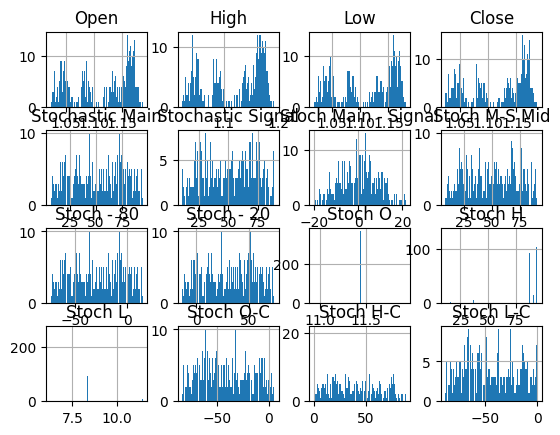

In [ ]:
data.iloc[:,1:].hist(bins=100)

In [ ]:
data.iloc[:,1:].corr()

,Open,High,Low,Close,Stochastic Main,Stochastic Signal,Stoch Main - Signal,Stoch M-S Mid,Stoch - 80,Stoch - 20,Stoch O,Stoch H,Stoch L,Stoch O-C,Stoch H-C,Stoch L-C
Open,1.000000,0.997133,0.997829,0.995113,0.145451,0.175703,-0.015234,0.162101,0.145451,0.145451,NaN,0.287572,-0.584436,-0.145451,0.020747,-0.170644
High,0.997133,1.000000,0.996411,0.997902,0.157475,0.182341,0.002119,0.171794,0.157475,0.157475,NaN,0.298170,-0.597474,-0.157475,0.014909,-0.183116
Low,0.997829,0.996411,1.000000,0.997668,0.152812,0.176381,0.003378,0.166444,0.152812,0.152812,NaN,0.283628,-0.584631,-0.152812,0.011193,-0.177918
Close,0.995113,0.997902,0.997668,1.000000,0.164795,0.182281,0.022361,0.175769,0.164795,0.164795,NaN,0.292967,-0.594986,-0.164795,0.004673,-0.190225
Stochastic Main,0.145451,0.157475,0.152812,0.164795,1.000000,0.934347,0.541033,0.985878,1.000000,1.000000,NaN,0.273294,-0.259108,-1.000000,-0.834181,-0.998998
Stochastic Signal,0.175703,0.182341,0.176381,0.182281,0.934347,1.000000,0.205809,0.980831,0.934347,0.934347,NaN,0.335457,-0.301574,-0.934347,-0.733488,-0.936167
Stoch Main - Signal,-0.015234,0.002119,0.003378,0.022361,0.541033,0.205809,1.000000,0.392555,0.541033,0.541033,NaN,-0.041185,0.000179,-0.541033,-0.559703,-0.533986
Stoch M-S Mid,0.162101,0.171794,0.166444,0.175769,0.985878,0.980831,0.392555,1.000000,0.985878,0.985878,NaN,0.307078,-0.283399,-0.985878,-0.800819,-0.986185
Stoch - 80,0.145451,0.157475,0.152812,0.164795,1.000000,0.934347,0.541033,0.985878,1.000000,1.000000,NaN,0.273294,-0.259108,-1.000000,-0.834181,-0.998998
Stoch - 20,0.145451,0.157475,0.152812,0.164795,1.000000,0.934347,0.541033,0.985878,1.000000,1.000000,NaN,0.273294,-0.259108,-1.000000,-0.834181,-0.998998


In [ ]:
data.iloc[:,1:].var()

,0
Open,2.673919e-03
High,2.654317e-03
Low,2.679380e-03
Close,2.675806e-03
Stochastic Main,5.936164e+02
Stochastic Signal,4.384253e+02
Stoch Main - Signal,7.872141e+01
Stoch M-S Mid,4.963405e+02
Stoch - 80,5.936164e+02
Stoch - 20,5.936164e+02


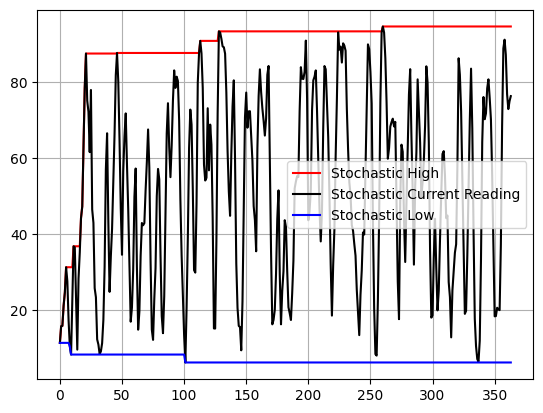

In [ ]:
plt.plot(data['Stoch H'],color='red')
plt.plot(data['Stochastic Main'],color='black')
plt.plot(data['Stoch L'],color='blue')
plt.grid()
plt.legend(['Stochastic High','Stochastic Current Reading','Stochastic Low'])

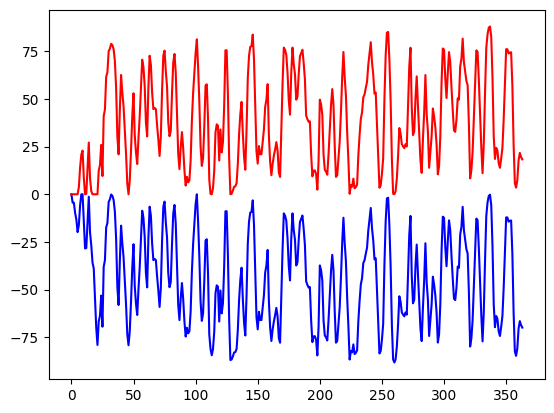

In [ ]:
plt.plot(data["Stoch L-C"],color="blue")
plt.plot(data["Stoch H-C"],color="red")

Text(0.5, 1.0, 'Open')

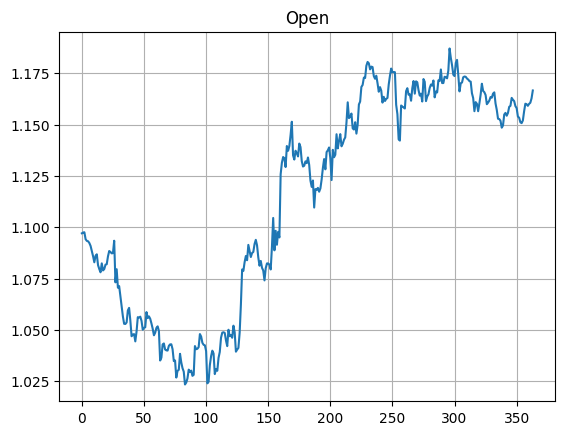

In [ ]:
index = 1
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'High')

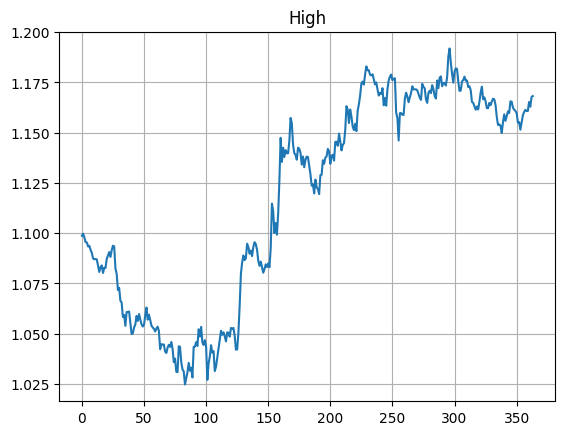

In [ ]:
index = 2
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Low')

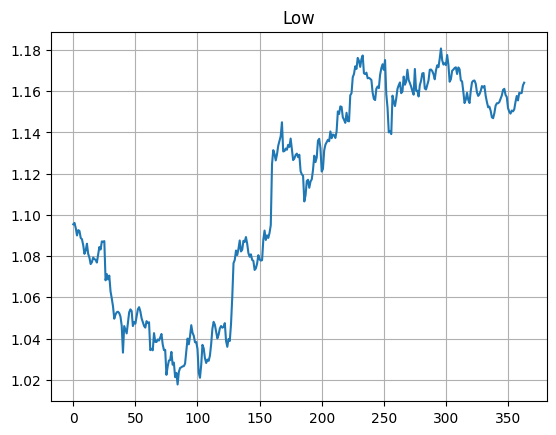

In [ ]:
index = 3
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Close')

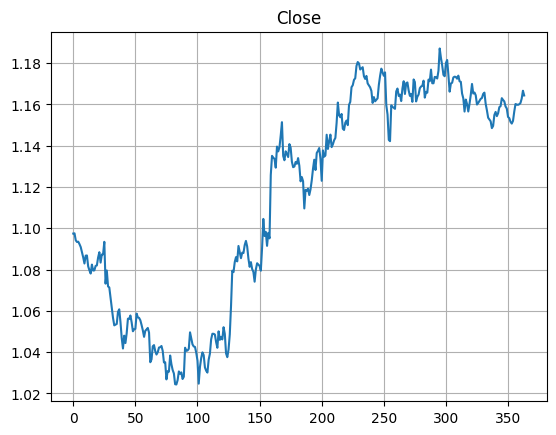

In [ ]:
index = 4
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Stochastic Main')

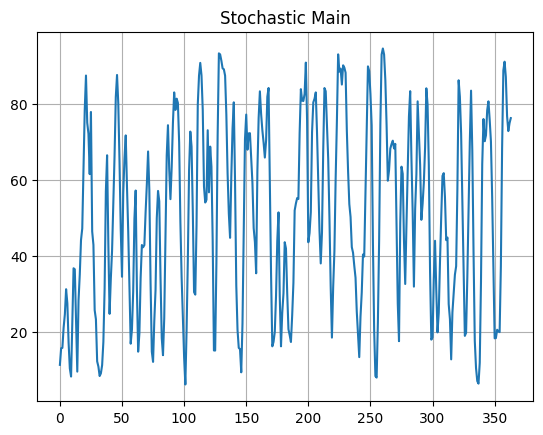

In [ ]:
index = 5
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Stochastic Signal')

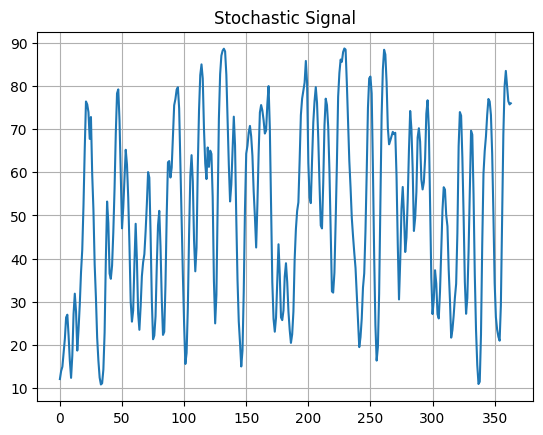

In [ ]:
index = 6
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Stoch Main - Signal')

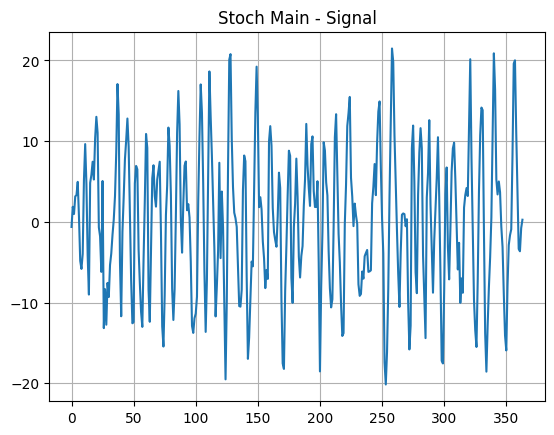

In [ ]:
index = 7
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Stoch M-S Mid')

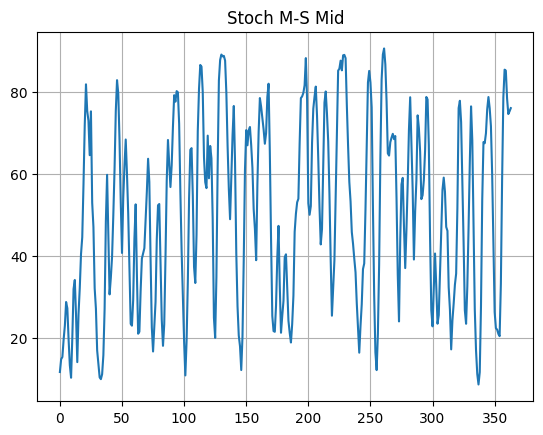

In [ ]:
index = 8
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

Text(0.5, 1.0, 'Stoch - 80')

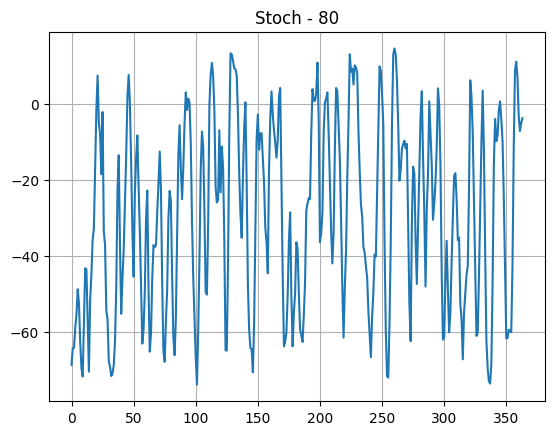

In [ ]:
index = 9
plt.grid()
plt.plot(data.iloc[:,index])
plt.title(data.iloc[:,[index]].columns[0])

In [ ]:
from sklearn.linear_model    import LinearRegression
from sklearn.model_selection import cross_val_score,TimeSeriesSplit

In [ ]:
HORIZON = 5

In [ ]:
tscv = TimeSeriesSplit(n_splits=10,gap=HORIZON)

In [ ]:
data['Target'] = data['Stochastic Main'].shift(-HORIZON)
data = data.iloc[:-HORIZON,:]
data

,Time,Open,High,Low,Close,Stochastic Main,Stochastic Signal,Stoch Main - Signal,Stoch M-S Mid,Stoch - 80,Stoch - 20,Stoch O,Stoch H,Stoch L,Stoch O-C,Stoch H-C,Stoch L-C,Target
0,2024.10.07 00:00:00,1.09705,1.09868,1.09542,1.09743,11.430045,12.060839,-0.630795,11.745442,-68.569955,-8.569955,11.430045,11.430045,11.430045,0.000000,0.000000,0.000000,31.305842
1,2024.10.08 00:00:00,1.09743,1.09971,1.09609,1.09754,15.800763,13.930801,1.869962,14.865782,-64.199237,-4.199237,11.430045,15.800763,11.430045,-4.370718,0.000000,-4.370718,27.617709
2,2024.10.09 00:00:00,1.09754,1.09787,1.09361,1.09415,15.889831,14.910316,0.979515,15.400073,-64.110169,-4.110169,11.430045,15.889831,11.430045,-4.459786,0.000000,-4.459786,17.312860
3,2024.10.10 00:00:00,1.09415,1.09547,1.09001,1.09334,21.223386,18.066851,3.156535,19.645119,-58.776614,1.223386,11.430045,21.223386,11.430045,-9.793342,0.000000,-9.793342,10.492424
4,2024.10.11 00:00:00,1.09334,1.09537,1.09260,1.09349,24.705882,21.386367,3.319516,23.046125,-55.294118,4.705882,11.430045,24.705882,11.430045,-13.275838,0.000000,-13.275838,8.361204
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
354,2025.11.24 00:00:00,1.15071,1.15504,1.15019,1.15201,20.034642,20.951270,-0.916628,20.492956,-59.965358,0.034642,11.430045,94.552586,6.277552,-8.604597,74.517944,-13.757090,87.068966
355,2025.11.25 00:00:00,1.15202,1.15860,1.15116,1.15646,37.311083,29.131177,8.179906,33.221130,-42.688917,17.311083,11.430045,94.552586,6.277552,-25.881038,57.241503,-31.033531,76.780671
356,2025.11.26 00:00:00,1.15646,1.16022,1.15470,1.16019,68.343480,48.737328,19.606151,58.540404,-11.656520,48.343480,11.430045,94.552586,6.277552,-56.913435,26.209106,-62.065927,72.849639
357,2025.11.27 00:00:00,1.16018,1.16134,1.15765,1.15995,88.787402,68.762365,20.025037,78.774883,8.787402,68.787402,11.430045,94.552586,6.277552,-77.357357,5.765184,-82.509849,74.953903


In [ ]:
X_classic = data.iloc[:,1:7].columns
X_new     = data.iloc[:,7:-1].columns
X_all     = data.iloc[:,1:-1].columns
y         = 'Target'

In [ ]:
scores = []

In [ ]:
model = LinearRegression()

In [ ]:
scores.append(np.mean(np.abs(cross_val_score(model,data.loc[:,X_classic],data.loc[:,y],cv=tscv,scoring='neg_mean_squared_error'))))

In [ ]:
scores.append(np.mean(np.abs(cross_val_score(model,data.loc[:,X_new],data.loc[:,y],cv=tscv,scoring='neg_mean_squared_error'))))

In [ ]:
scores.append(np.mean(np.abs(cross_val_score(model,data.loc[:,X_all],data.loc[:,y],cv=tscv,scoring='neg_mean_squared_error'))))

In [ ]:
scores / np.min(scores)

array([1.40170226, 1.        , 3.29482382])

([<matplotlib.axis.XTick at 0x7c392e1d1b80>,
 [Text(0, 0, 'OHLC Features'),
  Text(1, 0, 'Custom Features'),
  Text(2, 0, 'All Features')])

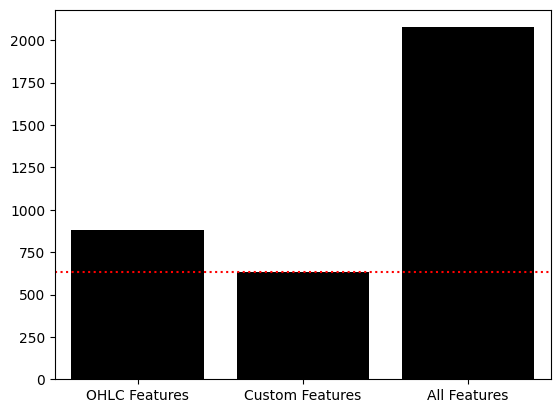

In [ ]:
sns.barplot(np.abs(scores),color='black')
plt.axhline(np.min(scores),linestyle=':',color='red')
plt.xticks([0,1,2],['OHLC Features','Custom Features','All Features'])

In [ ]:
from sklearn.linear_model import Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import LinearSVR

In [ ]:
models = [LinearRegression(),Ridge(),Lasso(),RandomForestRegressor(),GradientBoostingRegressor(),LinearSVR()]

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

([<matplotlib.axis.XTick at 0x7c392e9e69c0>,
 [Text(0, 0, 'LinearRegression()'),
  Text(1, 0, 'Ridge()'),
  Text(2, 0, 'Lasso()'),
  Text(3, 0, 'RandomForestRegressor()'),
  Text(4, 0, 'GradientBoostingRegressor()'),
  Text(5, 0, 'LinearSVR()')])

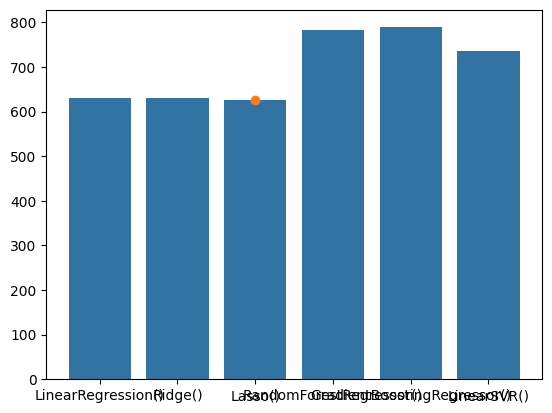

In [ ]:
scores = []

for i in np.arange(len(models)):
  model = models[i]
  scores.append(np.mean(np.abs(cross_val_score(model,data.loc[:,X_new],data.loc[:,y],cv=tscv,scoring='neg_mean_squared_error'))))

sns.barplot(scores)
plt.scatter(np.argmin(scores),np.min(scores))
plt.xticks(np.arange(len(models)),models)

In [ ]:
from sklearn.feature_selection import mutual_info_regression

In [ ]:
scores = mutual_info_regression(data.loc[:,X_new],data.loc[:,'Target'])

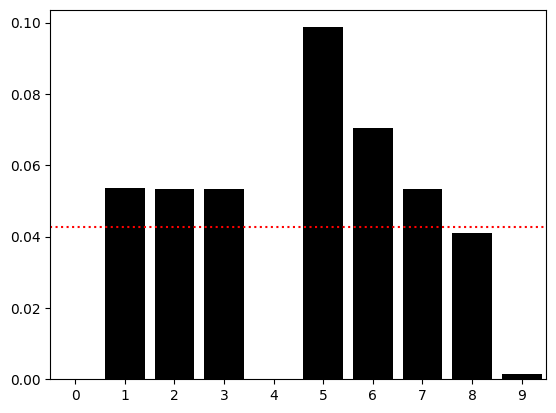

In [ ]:
sns.barplot(scores,color='black')
plt.axhline(np.mean(scores),color='red',linestyle=':')

In [ ]:
model = Lasso()

In [ ]:
model.fit(data.loc[:,X_new],data['Target'])

Lasso()

<Axes: >

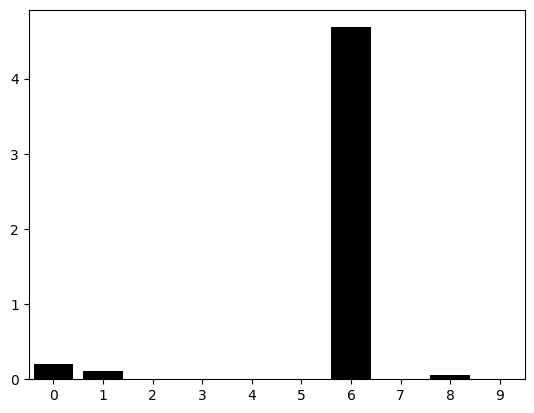

In [ ]:
sns.barplot(np.abs(model.coef_),color='black')

In [ ]:
!pip install onnx skl2onnx

  Using cached onnx-1.20.0-cp312-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (8.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 104.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.5/315.5 kB 24.8 MB/s eta 0:00:00


In [ ]:
import onnx
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

In [ ]:
initial_types = [('float input',FloatTensorType([1,len(X_new)]))]

In [ ]:
model = GradientBoostingRegressor()

model.fit(train.loc[:,X_new],train.iloc[:,-1])

GradientBoostingRegressor()

In [ ]:
onnx_proto = convert_sklearn(model,initial_types=initial_types,target_opset=12)

In [ ]:
onnx.save(onnx_proto,'EURUSD Stochastic GBR AI.onnx')

In [ ]:
len(X_new)

10